# MLP và backpropagation

Phép XOR của hai bit không tách được bằng một đường thẳng: hai điểm (0, 0), (1, 1) cho 0 và hai điểm (0, 1), (1, 0) cho 1 nằm chéo nhau. Vì vậy model tuyến tính như logistic regression không học được XOR. MLP (multilayer perceptron) xếp nhiều lớp tuyến tính, xen giữa là một hàm phi tuyến gọi là activation, để các lớp đầu tạo ra đặc trưng mới cho lớp sau. Để huấn luyện MLP cần tính đạo hàm của loss theo trọng số ở mọi lớp; thuật toán làm việc đó là backpropagation, nội dung chính của bài.

> **Mục tiêu**
>
> - Hiểu vì sao cần lớp ẩn và activation, qua ví dụ XOR.
> - Ghi shape ở mỗi lớp của mạng hai lớp.
> - Tính backpropagation bằng tay, cài bằng NumPy và so với PyTorch.

## Vì sao thêm một lớp?

Với đầu vào $x_1,x_2$ thuộc $\{0,1\}$, XOR có nhãn 1 tại $(0,1),(1,0)$ và nhãn 0 ở hai góc còn lại. Một đường thẳng không tách được hai cặp góc đối diện. Đây là giới hạn của kiến trúc: train lâu hơn cũng không chữa được.



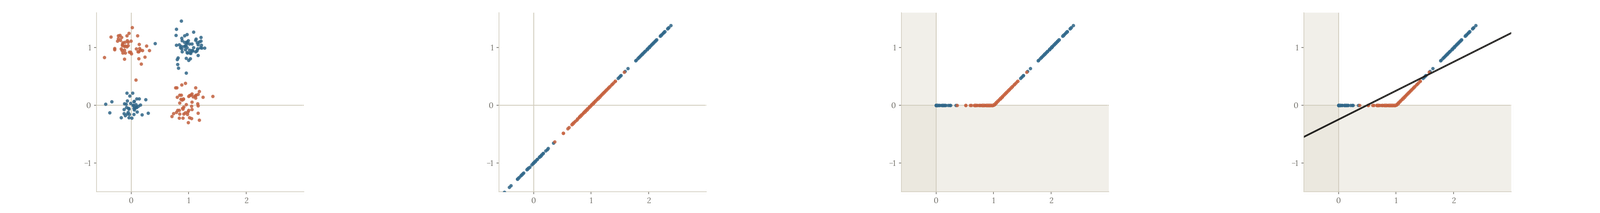

Tạo hai đặc trưng $h_1=\operatorname{ReLU}(x_1+x_2)$ và $h_2=\operatorname{ReLU}(x_1+x_2-1)$, với $\operatorname{ReLU}(z)=\max(0,z)$. Khi tổng là 0, 1, 2, hai đặc trưng lần lượt là $(0,0),(1,0),(2,1)$. Công thức $\hat y=h_1-2h_2$ cho 0, 1, 0, đúng XOR. Đây là một mạng được **đặt trọng số bằng tay**, chưa phải mạng đã học.

In [ ]:
import numpy as np
import torch

torch.set_num_threads(1)
torch.manual_seed(11)
np.set_printoptions(precision=4, suppress=True)
X_xor = np.array([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
hidden = np.maximum(X_xor @ np.ones((2, 2)) + [0., -1.], 0.)
print(hidden)
print(hidden @ np.array([1., -2.]))

[[0. 0.]
 [1. 0.]
 [1. 0.]
 [2. 1.]]
[0. 1. 1. 0.]


Dòng cuối cần cho `0, 1, 1, 0`. Hidden layer đã biến bốn góc thành những vị trí mà lớp sau kết hợp được: hai góc $(0,1),(1,0)$ cùng rơi vào điểm $(h_1,h_2)=(1,0)$, còn góc $(1,1)$ bị đẩy ra $(2,1)$.

**Hỏi nhanh.** Giữ nguyên hai đặc trưng $h_1$, $h_2$ của mạng XOR đặt tay, chỉ đổi đầu ra thành $\hat y = h_1 - h_2$. Với bốn đầu vào $(0,0)$, $(0,1)$, $(1,0)$, $(1,1)$, mạng cho ra hàm nào?

- A. OR: $0, 1, 1, 1$
- B. AND: $0, 0, 0, 1$
- C. Vẫn là XOR: $0, 1, 1, 0$
- D. NAND: $1, 1, 1, 0$

<details><summary>Đáp án</summary>

A. OR: $0, 1, 1, 1$

Khi tổng bằng 2 thì $(h_1, h_2) = (2, 1)$, nên $h_1 - h_2 = 1$. Hai tổng còn lại vẫn cho 0 và 1 như cũ. Lớp ẩn không đổi, chỉ cách lớp cuối trộn các đặc trưng thay đổi, mà mạng đã thành một hàm khác. AND cần $(0,1)$ cho ra 0. NAND cần $(0,0)$ cho ra 1. XOR cần hệ số $-2$ để góc $(1,1)$ về 0.

</details>

Nếu bỏ activation, hai lớp gộp lại: $(XW_1+b_1)W_2+b_2=X(W_1W_2)+(b_1W_2+b_2)$, vẫn là một lớp linear. Thêm tham số mà không thêm phi tuyến không giải quyết được XOR.

Xếp nhiều lớp như vậy là được một mạng nơ-ron nhiều lớp (multilayer perceptron, MLP). Các lớp nằm giữa đầu vào và đầu ra gọi là lớp ẩn; nhiều lớp ẩn thì gọi là mạng sâu.

Một nơ-ron ngưỡng, ra 1 khi $w_1x_1 + w_2x_2 + b > 0$, tính được AND, OR hay NAND; ví dụ $w = (-1, -1)$, $b = 1.5$ cho NAND. Nhưng nó chỉ vẽ được một đường, nên XOR cần ít nhất hai nơ-ron ẩn. Cũng vậy, muốn biết một điểm có nằm trong tam giác không, dùng ba nơ-ron ẩn, mỗi cái kiểm một cạnh, rồi nơ-ron ra làm phép AND.

Đường thẳng trong mặt phẳng tách được mọi cách gán nhãn của 3 điểm không thẳng hàng, nhưng không với 4 điểm: bốn góc XOR là ví dụ, và bỏ đi một góc thì ba góc còn lại lại tách được.



**Hỏi nhanh.** Mạng $2 \to 100 \to 1$ gồm hai lớp linear nối thẳng, không có activation ở giữa. Mạng này biểu diễn được những hàm nào?

- A. Mọi hàm liên tục, nhờ 100 neuron ẩn
- B. Đúng những hàm mà một lớp linear biểu diễn được
- C. Thêm được XOR, nhờ lớp ẩn tạo ra đặc trưng mới
- D. Nhiều hơn một lớp linear, nhưng chưa tới XOR

<details><summary>Đáp án</summary>

B. Đúng những hàm mà một lớp linear biểu diễn được

Tích $W_1W_2$ là một ma trận $2 \times 1$, còn bias gộp lại thành một số, nên 100 neuron ẩn chỉ là tham số thừa. Khả năng biểu diễn hàm phức tạp đến từ phần phi tuyến ở giữa, không đến từ số neuron. Không có phi tuyến thì cũng chẳng có mức nào ở giữa một lớp linear và XOR.

</details>

## Forward có bảng shape

Ta thống nhất mẫu nằm ở hàng. Một batch $X$ có shape `(B, d)`, hidden width $h$, đầu ra $c$:

$$Z_1=XW_1+b_1,\qquad H=\operatorname{ReLU}(Z_1),\qquad P=HW_2+b_2.$$

| Tên | Shape | Ý nghĩa |
|---|---|---|
| $W_1,b_1$ | `(d, h)`, `(h,)` | Tạo hidden feature |
| $Z_1,H$ | `(B, h)` | Trước và sau activation |
| $W_2,b_2$ | `(h, c)`, `(c,)` | Tạo đầu ra |
| $P,Y$ | `(B, c)` | Dự đoán và target |

Trong NumPy ta dùng cách viết hàng như bảng này. `torch.nn.Linear(d,h)` lưu `weight` shape `(h,d)` và thực hiện $X\,\text{weight}^\top+b$. Hai quy ước cùng đúng; khi chuyển trọng số tự viết sang `Linear`, cần chuyển vị. Nếu copy thẳng ma trận vuông thì shape vẫn hợp lệ nhưng nội dung có thể sai.

Mỗi nơ-ron của lớp nối với mọi đầu vào của lớp trước, nên gọi là lớp kết nối đầy đủ (fully connected); `nn.Linear(10, 3)` là lớp 10 vào, 3 ra. Số trọng số giữa hai lớp bằng số vào nhân số ra, cộng thêm số ra nếu có bias: mạng $30 \to 4 \to 3 \to 1$ không bias có $120 + 12 + 3 = 135$ trọng số.

Forward phải lưu $X,Z_1,H$ cho backward, vì đạo hàm phụ thuộc chúng. Đó là nguồn chi phí activation memory: nhớ giá trị trung gian để khỏi tính lại. Backprop là thuật toán đi ngược các phép, còn autograd là cơ chế thư viện xây graph và gọi đạo hàm phù hợp.

**Hỏi nhanh.** Lớp đầu đã được cài bằng NumPy theo quy ước hàng, $Z = XW_1$, với `W1` có shape `(3, 3)`. Chép thẳng `W1` vào `weight` của `torch.nn.Linear(3, 3)` rồi chạy. Chuyện gì xảy ra?

- A. Báo lỗi shape ngay ở lần forward đầu tiên
- B. Ra đúng kết quả, vì PyTorch tự chuyển vị khi cần
- C. Chạy êm, nhưng tính ra $XW_1^\top$, sai mà không báo
- D. Chỉ bias bị sai, phần trọng số vẫn đúng

<details><summary>Đáp án</summary>

C. Chạy êm, nhưng tính ra $XW_1^\top$, sai mà không báo

`Linear` tính $X\,\text{weight}^\top + b$, nên gán `weight = W1` sẽ cho ra $XW_1^\top$. Ma trận vuông nên mọi phép nhân đều khớp shape và không có lỗi nào được báo. Phải gán `W1.T`. Chỉ khi ma trận không vuông thì phép nhân mới lệch shape và báo lỗi. PyTorch không đoán quy ước của người viết, và bias không liên quan đến chuyển vị.

</details>

## Từ loss về lớp đầu

Để dễ kiểm, ta dùng hồi quy một đầu ra $c=1$ và $J=\frac1B\sum_i(P_i-Y_i)^2$. Bài 3.3 sẽ đổi sang loss phân loại. Đặt $G_2=\partial J/\partial P=2(P-Y)/B$, shape `(B,1)`. Với lớp linear cuối:

$$\frac{\partial J}{\partial W_2}=H^\top G_2,\qquad
\frac{\partial J}{\partial b_2}=\sum_iG_{2,i}.$$

Đạo hàm theo hidden là $G_2W_2^\top$. Khi có nhiều đầu ra, mỗi hidden neuron nối tới tất cả nên ảnh hưởng tới loss qua nhiều đường; chain rule cộng đóng góp của các đường ấy, và phép nhân ma trận làm sẵn phép cộng này.

Gradient theo $W_1$ cần $\partial J/\partial Z_1$. Đại lượng này phụ thuộc mọi lớp phía sau nên chỉ có khi backward đổ về; còn đạo hàm cục bộ của activation thì tính được ngay lúc forward.

Qua ReLU, phần có $Z_1<0$ không đổi đầu ra khi xê dịch nhỏ nên gradient bằng 0; phần $Z_1>0$ đi qua nguyên vẹn:

$$G_1=(G_2W_2^\top)\odot\mathbf{1}[Z_1>0],\qquad
\frac{\partial J}{\partial W_1}=X^\top G_1,\qquad
\frac{\partial J}{\partial b_1}=\sum_iG_{1,i}.$$

$\odot$ là nhân từng phần tử, không phải nhân ma trận. Vài hệ quả và quy ước:

- Tại đúng 0, ReLU không có đạo hàm; ta và PyTorch chọn gradient 0. Khi kiểm bằng sai phân, tránh đặt điểm đúng chỗ gãy ấy.
- Nếu loss lấy trung bình trên nhiều đầu ra $c$, hệ số sẽ là $2/(Bc)$; công thức ở đây dùng $c=1$.
- Gradient của trọng số nối đầu vào $j$ với nơ-ron $i$ bằng 0 khi $x_j = 0$ hoặc khi nơ-ron đó đóng ($z_i < 0$), bất kể gradient đổ về là bao nhiêu.
- Với `nn.Linear`, weight có shape (out, in) và $Y = XW^\top + b$, nên $\partial L/\partial W = G^\top X$ với $G = \partial L/\partial Y$.

Vì gradient của một nơ-ron đi qua chính trọng số của nó, nếu mọi trọng số của một lớp bằng nhau thì các nơ-ron trong lớp nhận cùng gradient và mãi giống nhau; khởi tạo ngẫu nhiên là để phá đối xứng ấy.

Hình dưới vẽ đường đi ấy cho mạng $2\to3\to1$ sẽ dựng bằng PyTorch ở mục dùng thư viện: gradient từ $J$ về $P$, nhân $W_2^\top$ để về $H$, qua cổng ReLU′ rồi mới tới lớp đầu.



**Hỏi nhanh.** `H` có shape `(5, 4)`, `G2` có shape `(5, 1)`. Gradient theo `W2` có shape gì?

- A. `(5, 5)`
- B. `(5, 4)`
- C. `(1, 4)`
- D. `(4, 1)`

<details><summary>Đáp án</summary>

D. `(4, 1)`

`H.T @ G2` nhân `(4, 5)` với `(5, 1)`, cộng đóng góp của năm mẫu lại thành `(4, 1)`, đúng shape của $W_2$. Gradient luôn có cùng shape với tham số. `(1, 4)` là `G2.T @ H`, tức chuyển vị của đáp án. `(5, 4)` là shape của chính $H$. `(5, 5)` xuất hiện khi nhân theo chiều mẫu thay vì cộng qua các mẫu.

</details>

## Ví dụ tính tay

Lấy một mẫu $x=2$, $y=0$, mạng một hidden neuron: $w_1=0.5,b_1=0,w_2=2,b_2=0$. Forward có $z_1=1,h=1,p=2,J=4$. Bắt đầu từ đầu ra: $dJ/dp=4$, nên $dJ/dw_2=4h=4$ và $dJ/db_2=4$. Truyền về hidden cho $dJ/dh=4w_2=8$; ReLU đang mở vì $z_1>0$, nên $dJ/dw_1=8x=16$, $dJ/db_1=8$.

Các gradient dùng **trọng số trước cập nhật**. Nếu sửa $w_2$ rồi mới tính gradient lớp đầu, đang trộn hai mạng khác nhau trong cùng lượt backward. Tính đủ gradient trước, cập nhật tất cả sau. Khi một neuron âm ở mọi mẫu, gradient qua ReLU của nó bằng 0; vấn đề này sẽ nối sang activation ở bài tiếp.



**Hỏi nhanh.** Mạng một mẫu có $h = \mathrm{ReLU}(w_1x)$, $p = w_2h$, $L = (p - y)^2$. Tại $x = 3$, $w_1 = 1$, $w_2 = 1$, $y = 1$, gradient $\partial L/\partial w_1$ bằng bao nhiêu?

- A. 6
- B. 3
- C. 12
- D. 4

<details><summary>Đáp án</summary>

C. 12

Forward cho $h = 3$, $p = 3$. Đi ngược lại: $\partial L/\partial p = 2(3 - 1) = 4$, nhân $w_2 = 1$, nhân đạo hàm ReLU bằng 1 vì $w_1x > 0$, rồi nhân $x = 3$, được 12. Ra 6 là quên hệ số 2 của đạo hàm bình phương. Ra 4 là quên nhân $x$. Ra 3 là chỉ giữ lại thừa số $x$.

</details>

## Cài nhỏ bằng NumPy

Ta kiểm trên hai mẫu, hai hidden neuron và điểm không nằm ở chỗ gãy. Tách forward/backward thành hàm để cùng một code phục vụ tính gradient và thử loss sau cập nhật:

In [ ]:
X = np.array([[1., 2.], [2., -1.]])
Y = np.array([[1.], [0.]])
params = [np.array([[.2, -.3], [.4, .1]]), np.array([.1, .2]),
          np.array([[.5], [-.4]]), np.array([.05])]

def forward(params):
    W1, b1, W2, b2 = params
    Z1 = X @ W1 + b1
    H = np.maximum(Z1, 0)
    P = H @ W2 + b2
    return P, (Z1, H)

def objective(params):
    P, _ = forward(params)
    assert P.shape == Y.shape
    return np.mean((P - Y) ** 2)

def backward(params):
    P, (Z1, H) = forward(params)
    G2 = 2 * (P - Y) / len(X)
    G1 = (G2 @ params[2].T) * (Z1 > 0)
    return [X.T @ G1, G1.sum(axis=0), H.T @ G2, G2.sum(axis=0)]

print(forward(params)[0].ravel())
print(round(objective(params), 6))
for g in backward(params):
    print(g)

[0.56 0.1 ]
0.1018
[[-0.12   0.176]
 [-0.49   0.352]]
[-0.17   0.176]
[[-0.474]
 [-0.044]]
[-0.34]


Hai dự đoán là $0.56$ và $0.10$, nên loss tính tay $(0.44^2+0.10^2)/2=0.1018$. Kiểm từng ma trận gradient cùng shape với trọng số tương ứng. Chẳng hạn $dJ/dW_2$ hàng đầu bằng $1.1(-0.44)+0.1(0.10)=-0.474$; đây là tổng hai đường đóng góp qua hai mẫu. Ở batch này $Z_1=\begin{bmatrix}1.1&0.1\\0.1&-0.5\end{bmatrix}$: neuron ẩn thứ hai đóng ở mẫu thứ hai, và mask `(Z1 > 0)` chặn gradient qua đúng ô đó.



**Hỏi nhanh.** Hàm `backward` ở trên bị quên `* (Z1 > 0)`. Với $Z_1$ của batch này, những gradient nào bị sai?

- A. Cả bốn gradient, vì $G_1$ có mặt trong mọi công thức
- B. Chỉ phần $W_1$, $b_1$ nối vào neuron ẩn thứ hai
- C. Chỉ $W_2$ và $b_2$, vì chúng nằm sát ReLU nhất
- D. Không gradient nào, vì forward đã cắt $H$ về 0

<details><summary>Đáp án</summary>

B. Chỉ phần $W_1$, $b_1$ nối vào neuron ẩn thứ hai

Mask chỉ có một số 0, ở mẫu 2, neuron 2. Bỏ mask thì đóng góp của ô ấy lọt vào cột hai của $G_1$. Vì vậy cột hai của gradient $W_1$ và phần tử thứ hai của gradient $b_1$ bị sai. Chạy thử thì thấy $0.176 \to 0.096$, $0.352 \to 0.392$ và $0.176 \to 0.136$, còn cột một không đổi. Gradient của $W_2$, $b_2$ chỉ dùng $H$ và $G_2$, không đi qua mask. Forward có cắt $H$ về 0, nhưng backward vẫn phải tự nhân đạo hàm của ReLU. Phép kiểm bằng sai phân ở mục sau sẽ bắt được lỗi này.

</details>

## Đối chiếu độc lập rồi mới học

Sai phân trung tâm ước lượng đạo hàm theo một phần tử tham số $\theta_k$ bằng $\big(J(\theta_k+\varepsilon)-J(\theta_k-\varepsilon)\big)/(2\varepsilon)$, giữ nguyên các phần tử khác. Mỗi phần tử tốn hai lần tính loss. Cách này chậm nhưng không dùng chung công thức nào với backward, giống lời giải brute force dùng để kiểm thuật toán tối ưu trong CP.

Ta dùng `float64` và $\varepsilon=10^{-5}$: sai số của sai phân trung tâm cỡ $\varepsilon^2$, sai số làm tròn của `float64` còn nhỏ hơn, nên so với ngưỡng `atol=1e-8` là đủ chặt. Với `float32`, sai số làm tròn bị khuếch đại khi chia cho $2\varepsilon$, nên khi kiểm hãy chuyển mạng tí hon sang `float64`. Mọi phần tử của $Z_1$ cách 0 ít nhất $0.1$, xa hơn nhiều so với bước xê dịch, nên phép thử không vượt qua chỗ gãy của ReLU.

In [ ]:
def numerical_gradient(params, eps=1e-5):
    answer = []
    for p in params:
        g = np.zeros_like(p)
        for index in np.ndindex(p.shape):
            old = p[index]
            p[index] = old + eps
            plus = objective(params)
            p[index] = old - eps
            minus = objective(params)
            p[index] = old
            g[index] = (plus - minus) / (2 * eps)
        answer.append(g)
    return answer

manual = backward(params)
numeric = numerical_gradient(params)
print('numeric match:', all(np.allclose(a, b, atol=1e-8)
                            for a, b in zip(manual, numeric)))

tp = [torch.tensor(p, dtype=torch.float64, requires_grad=True) for p in params]
tx, ty = torch.tensor(X), torch.tensor(Y)
pred = torch.relu(tx @ tp[0] + tp[1]) @ tp[2] + tp[3]
((pred - ty) ** 2).mean().backward()
print('autograd match:', all(np.allclose(g, p.grad.numpy(), atol=1e-10)
                            for g, p in zip(manual, tp)))
updated = [p - .05 * g for p, g in zip(params, manual)]
print(round(objective(params), 6), round(objective(updated), 6))

numeric match: True
autograd match: True
0.1018 0.065513


Hai dòng `True` nói backward khớp với hai cách tính độc lập tại bộ tham số đã chọn. Dòng cuối cho thấy một bước gradient descent với learning rate $0.05$ đưa loss từ $0.1018$ xuống $0.065513$. Hai loại bằng chứng này không thay được nhau. Loss giảm sau một bước chỉ cần hướng cập nhật đi xuống, nên một backward sai ở vài phần tử vẫn có thể làm loss giảm. Ngược lại, gradient đúng không hứa hội tụ tới nghiệm toàn cục, vì loss của mạng neural thường không lồi.

**Hỏi nhanh.** Mạng nhỏ ở trên có 9 phần tử tham số. Kiểm bằng sai phân trung tâm thì phải tính `objective` bao nhiêu lần? Với một MLP có $10^6$ tham số thì sao?

- A. 18 lần, và mạng $10^6$ tham số cần $2\cdot 10^6$ lần
- B. 9 lần, và mạng $10^6$ tham số cần $10^6$ lần
- C. 2 lần, số tham số không ảnh hưởng chi phí
- D. 4 lần, mỗi tensor một cặp, và mạng lớn vẫn chỉ 4 lần

<details><summary>Đáp án</summary>

A. 18 lần, và mạng $10^6$ tham số cần $2\cdot 10^6$ lần

$W_1$ có 4 phần tử, $b_1$ có 2, $W_2$ có 2, $b_2$ có 1, tổng là 9. Mỗi phần tử cần tính hai lần, với $+\varepsilon$ và $-\varepsilon$, nên tổng là 18 lần. Ra 9 là quên rằng sai phân trung tâm cần cả hai phía. Backward cho cả vector gradient với chi phí cỡ một lần forward, nên sai phân chỉ dùng để kiểm trên mạng tí hon, không dùng để train. Hai lần tính chỉ cho đạo hàm theo một hướng. Xê dịch cả tensor một lúc cũng chỉ cho một hướng như thế, không tách được đạo hàm của từng phần tử.

</details>

**Hỏi nhanh.** Gradient tính bằng NumPy trùng với autograd và với sai phân trên một batch nhỏ. Điều đó bảo đảm được gì?

- A. Mạng sẽ có điểm validation cao sau khi train
- B. Gradient descent sẽ tới được nghiệm toàn cục
- C. Mọi batch khác cũng sẽ cho loss giảm
- D. Backward tính đúng đạo hàm tại điểm đã kiểm

<details><summary>Đáp án</summary>

D. Backward tính đúng đạo hàm tại điểm đã kiểm

Phép kiểm so hai cách tính cùng một đạo hàm, tại một bộ tham số. Nó không nói gì về khả năng tổng quát hóa, vì việc ấy cần validation. Nó cũng không biến một loss không lồi thành lồi, và một bước giảm loss trên batch này không hứa gì cho batch khác. Muốn tin code hơn, hãy kiểm thêm vài bộ tham số ngẫu nhiên.

</details>

## Dùng thư viện ở đúng tầng

Khi đã hiểu cơ chế, bài thực tế viết `torch.nn.Sequential(torch.nn.Linear(d,h), torch.nn.ReLU(), torch.nn.Linear(h,c))` để thư viện quản lý tham số và autograd lo phần backward. Trước khi train, nên hỏi lại mô hình hai điều: output có shape như dự tính không, và mạng có bao nhiêu tham số:

In [ ]:
model = torch.nn.Sequential(torch.nn.Linear(2, 3), torch.nn.ReLU(),
                            torch.nn.Linear(3, 1))
print(tuple(model(torch.zeros(4, 2)).shape))
print(sum(p.numel() for p in model.parameters()))

(4, 1)
13


Đầu ra `(4,1)` là bốn dự đoán. Số tham số là $2\cdot3+3+3\cdot1+1=13$, tính cả hai bias; layer ReLU không có tham số học. Hai lỗi hay gặp khi tự viết model:

- Lớp con phải được gán làm thuộc tính của `nn.Module` hoặc đặt trong `nn.ModuleList`. Để trong list Python thường thì `model.parameters()` không thấy, optimizer không học và `.to(device)` cũng bỏ sót.
- Dùng cùng một đối tượng lớp ở hai chỗ, như `nn.Sequential(l, nn.ReLU(), l)`, là chia sẻ trọng số: `parameters()` chỉ đếm một lần và gradient cộng từ cả hai chỗ.

Đầu ra và loss phải đi cùng nhau: phân loại nhị phân dùng một logit với BCEWithLogitsLoss, nhiều lớp loại trừ nhau dùng $c$ logits với CrossEntropyLoss (bài 3.3).

**Hỏi nhanh.** Mạng hồi quy trả về `pred` shape `(4, 1)`, giá trị đúng bằng target `y = torch.tensor([1., 2., 3., 4.])` có shape `(4,)`. Thế nhưng `torch.nn.MSELoss()(pred, y)` lại cho $2.5$ thay vì $0$. Vì sao?

- A. `MSELoss` mặc định cộng các bình phương thay vì lấy trung bình
- B. Sai số làm tròn của `float32` cộng dồn qua bốn mẫu
- C. `pred - y` bị broadcast thành `(4, 4)`, so mọi cặp mẫu
- D. `y` phải đổi sang `float64` cho cùng kiểu với `pred`

<details><summary>Đáp án</summary>

C. `pred - y` bị broadcast thành `(4, 4)`, so mọi cặp mẫu

Trừ `(4, 1)` cho `(4,)` ra ma trận `(4, 4)`, với phần tử $(i, j)$ là $\text{pred}_i - y_j$. Loss là trung bình trên 16 cặp, trong đó 12 cặp là của hai mẫu khác nhau, nên ra $40/16 = 2.5$. PyTorch chỉ cảnh báo chứ không báo lỗi. Sửa bằng `y.view(-1, 1)` hoặc `pred.squeeze(1)`. Dòng `assert P.shape == Y.shape` trong `objective` ở trên có mặt chính để chặn lỗi này. Cộng thay vì trung bình thì vẫn ra 0 khi dự đoán đúng. Làm tròn không tạo ra sai lệch cỡ 2.5. Hai tensor vốn đã cùng kiểu `float32`.

</details>

## Khi đi thi

- **Học thuộc một batch nhỏ trước.** Cho mạng train trên vài chục mẫu đến khi loss gần 0. Không làm được thì lỗi nằm ở code (shape, mask ReLU, `detach`, thứ tự cập nhật, hệ số trung bình), chưa phải ở hyperparameter.
- **Tự viết backward thì kiểm sai phân trước.** Mạng tí hon, `float64`, điểm xa chỗ gãy của ReLU; khớp rồi mới chạy trên dữ liệu thật.
- **Đếm tham số và bộ nhớ trước khi train.** Một lớp ẩn có $dh+h+hc+c$ tham số và activation cỡ $Bh$ số; lớp nối với đầu vào lớn thường chiếm gần hết tham số.
- **So với baseline linear trên cùng split và seed.** MLP rộng hơn tốn thêm thời gian GPU nhưng không chắc tốt hơn trên validation.
- **Đề yêu cầu đặt trọng số tay** (hàm ngưỡng, không huấn luyện): mỗi neuron ẩn là một nửa mặt phẳng, neuron cuối ghép chúng bằng AND hoặc OR qua ngưỡng; thử lại trên đỉnh, cạnh và vài điểm ngoài.
- **Chép trọng số sang `nn.Linear` thì chuyển vị**, rồi so output hai bản trên vài mẫu.

## Tóm tắt

- Lớp ẩn tạo đặc trưng mới; activation là phần phi tuyến, thiếu nó thì nhiều lớp vẫn chỉ là một lớp linear.
- Backprop đi ngược graph, nhân độ nhạy cục bộ và cộng các nhánh. Qua ReLU, gradient bị chặn ở các ô âm.
- Gradient có cùng shape với tham số; tính đủ mọi gradient rồi mới cập nhật.
- Kiểm backward bằng sai phân và autograd trên mạng tí hon trước khi train thật.

## Kiểm tra cuối bài

**Câu 1.** Đề yêu cầu dựng một MLP chỉ gồm lớp linear và hàm ngưỡng $\Theta(z) = 1$ nếu $z \ge 0$, ngược lại bằng 0. Trọng số đặt tay, không huấn luyện. Đầu ra phải bằng 1 khi điểm $(x, y)$ nằm trong tam giác có đỉnh $(0,0)$, $(3,1)$, $(1,5)$, tính cả cạnh. Lớp ẩn có $h_1 = \Theta(3y - x)$, $h_2 = \Theta(7 - 2x - y)$, $h_3 = \Theta(5x - y)$. Chọn neuron đầu ra.

- A. $\Theta(h_1 + h_2 + h_3 - 1)$
- B. $\Theta(h_1 + h_2 + h_3 - 2)$
- C. $\Theta(h_1 + h_2 + h_3 - 3)$
- D. $\Theta(3 - h_1 - h_2 - h_3)$

<details><summary>Đáp án</summary>

C. $\Theta(h_1 + h_2 + h_3 - 3)$

Mỗi neuron ẩn bật trên một nửa mặt phẳng chứa tam giác, với biên là đường thẳng qua một cạnh. Chẳng hạn đường $3y - x = 0$ đi qua $(0,0)$ và $(3,1)$, còn đỉnh $(1,5)$ cho $14 > 0$. Tam giác là giao của ba nửa mặt phẳng, nên đầu ra cần phép AND, tức tổng phải bằng 3. Ngưỡng $-2$ nhận cả điểm $(2, 0)$, nằm ngoài tam giác nhưng chỉ vi phạm một cạnh. Ngưỡng $-1$ luôn cho 1, vì không điểm nào nằm ngoài cả ba nửa mặt phẳng. $\Theta(3 - h_1 - h_2 - h_3)$ cũng luôn bằng 1, vì tổng không vượt quá 3. Hàm ngưỡng có đạo hàm bằng 0 gần như khắp nơi, nên backprop không học được mạng này, và trọng số phải đặt tay.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 1 · Part 7.4](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-1-problems.pdf#page=19)

</details>

**Câu 2.** Mạng không có bias. $z_1 = w_Ax_1 + w_Bx_2$, $a_1 = g(z_1)$. Từ $a_1$ tách ra hai nhánh: $z_2 = w_Ca_1$, $a_2 = g(z_2)$ và $z_3 = w_Da_1$, $a_3 = g(z_3)$. Cuối cùng $z_4 = w_Ea_2 + w_Fa_3$, $\hat y = g(z_4)$. Đặt $\delta = \partial\ell/\partial z_4$. Biểu thức nào là $\partial\ell/\partial a_1$?

- A. $\delta\,\big(w_Eg'(z_2)w_C + w_Fg'(z_3)w_D\big)$
- B. $\delta\,w_Eg'(z_2)w_C$
- C. $\delta\,\big(w_Eg'(z_2)w_C\big)\big(w_Fg'(z_3)w_D\big)$
- D. $\delta\,\big(w_Ew_C + w_Fw_D\big)$

<details><summary>Đáp án</summary>

A. $\delta\,\big(w_Eg'(z_2)w_C + w_Fg'(z_3)w_D\big)$

$a_1$ ảnh hưởng tới loss qua hai đường: $a_1 \to z_2 \to a_2 \to z_4$ và $a_1 \to z_3 \to a_3 \to z_4$. Chain rule nhiều biến cộng đóng góp của các đường lại. Chỉ lấy một nhánh là quên đường thứ hai. Nhân hai nhánh với nhau là nhầm “đi song song” với “đi nối tiếp”. Bỏ $g'$ là coi activation như hàm đồng nhất. Từ đây có $\partial\ell/\partial w_A = \partial\ell/\partial a_1 \cdot g'(z_1)\cdot x_1$.
Phỏng theo: [CMU 10-601 · Exam 2 Practice · Q4.4](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam2_practice_problems.pdf#page=18)

</details>

**Câu 3.** Với `lin = torch.nn.Linear(2, 3)`, `lin.weight` và `lin.bias` có shape gì?

- A. `(2, 3)` và `(3,)`
- B. `(2, 3)` và `(2,)`
- C. `(3, 2)` và `(2,)`
- D. `(3, 2)` và `(3,)`

<details><summary>Đáp án</summary>

D. `(3, 2)` và `(3,)`

PyTorch lưu `weight` theo thứ tự (số đầu ra, số đầu vào), và tính $X\,\text{weight}^\top + b$. Bias có một số cho mỗi đầu ra. `(2, 3)` là shape của $W_1$ theo quy ước hàng trong bài, nên khi chép sang phải chuyển vị. Bias `(2,)` là nhầm số đầu vào với số đầu ra.

</details>

**Câu 4.** Ảnh xám $28 \times 28$ được duỗi thành vector, rồi đưa qua MLP $784 \to 128 \to 10$, cả hai lớp đều có bias. Mạng có bao nhiêu tham số?

- A. 100480
- B. 101632
- C. 101760
- D. 101770

<details><summary>Đáp án</summary>

D. 101770

Lớp đầu có $784 \cdot 128 + 128 = 100\,480$ tham số, lớp sau có $128 \cdot 10 + 10 = 1290$, tổng là 101770. Ra 100480 là chỉ đếm lớp đầu. Ra 101632 là bỏ cả hai bias. Ra 101760 là quên bias của lớp cuối. Gần như mọi tham số nằm ở lớp nối với đầu vào lớn, nên tăng độ phân giải ảnh thì lớp đầu phình ra nhanh nhất.

</details>

**Câu 5.** Mạng một đầu vào: $a_1 = w_{11}x + b_{11}$, $a_2 = w_{12}x + b_{12}$, $z_j = \mathrm{ReLU}(a_j)$, $a_3 = w_{21}z_1 + w_{22}z_2 + b_{21}$, $\hat y = \sigma(a_3)$. Loss là cross-entropy nhị phân, nên $\partial L/\partial a_3 = \hat y - y$. Ở một mẫu có $a_1 = 0.5$, $a_2 = -0.2$, với $w_{21} = 1$, $w_{22} = -1$. Gradient theo hai bias của lớp ẩn thế nào?

- A. $\partial L/\partial b_{11} = 0$ và $\partial L/\partial b_{12} = 0$
- B. $\partial L/\partial b_{11} \ne 0$ và $\partial L/\partial b_{12} = 0$
- C. $\partial L/\partial b_{11} = 0$ và $\partial L/\partial b_{12} \ne 0$
- D. $\partial L/\partial b_{11} \ne 0$ và $\partial L/\partial b_{12} \ne 0$

<details><summary>Đáp án</summary>

B. $\partial L/\partial b_{11} \ne 0$ và $\partial L/\partial b_{12} = 0$

Chuỗi đạo hàm cho $b_{12}$ là $\frac{\partial L}{\partial a_3}\cdot\frac{\partial a_3}{\partial z_2}\cdot\frac{\partial z_2}{\partial a_2}\cdot\frac{\partial a_2}{\partial b_{12}}$, trong đó $\partial z_2/\partial a_2 = 0$ vì $a_2 < 0$. Neuron 2 đang đóng, nên mẫu này không đẩy $b_{12}$. Với $b_{11}$, ReLU mở vì $a_1 > 0$, $w_{21} \ne 0$, và $\hat y - y \ne 0$ vì $\hat y$ nằm hẳn trong $(0, 1)$. Phương án cả hai khác 0 là quên cổng ReLU. Phương án ngược lại là nhầm neuron nào đóng. Phương án cả hai bằng 0 là tưởng một neuron đóng thì chặn gradient của cả lớp.
Phỏng theo: [CMU 10-601 · Exam 2 Practice · Q4.2(d)](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam2_practice_problems.pdf#page=15)

</details>

**Câu 6.** Mạng một lớp ẩn: $z_1 = w_{11}x_1 + w_{12}x_2$, $z_2 = w_{21}x_1 + w_{22}x_2$, $a_j = f(z_j)$ với $f$ là sigmoid. Đầu ra trước activation là $z = v_1a_1 + v_2a_2$. Loss được cộng thêm số hạng phạt $\lambda z^2$ cho từng mẫu. Đạo hàm của số hạng phạt này theo $w_{11}$ là gì?

- A. $2\lambda z\,v_1f'(z_1)\,x_1$
- B. $2\lambda z\,x_1$
- C. $2\lambda z\,v_1x_1$
- D. $2\lambda z\,f'(z)\,v_1f'(z_1)\,x_1$

<details><summary>Đáp án</summary>

A. $2\lambda z\,v_1f'(z_1)\,x_1$

Đi ngược lại: $\partial(\lambda z^2)/\partial z = 2\lambda z$, $\partial z/\partial a_1 = v_1$, $\partial a_1/\partial z_1 = f'(z_1)$, $\partial z_1/\partial w_{11} = x_1$. Phương án có $f'(z)$ là đi thêm qua sigmoid ở đầu ra, trong khi số hạng phạt đặt thẳng lên $z$ trước activation, nên chuỗi dừng ở $z$. Hai phương án ngắn bỏ qua lớp ẩn hoặc cổng sigmoid. Khác với phạt $\lambda w_{11}^2$ có đạo hàm $2\lambda w_{11}$, số hạng này phụ thuộc dữ liệu thông qua $z$.
Phỏng theo: [MIT 6.036 · Final, Spring 2022 · Q2(a)](https://introml.mit.edu/_static/fall22/final/review/6036_final_sp22.pdf#page=3)

</details>

**Câu 7.** Loss MSE lấy trung bình trên $B$ mẫu và $c$ đầu ra, như mặc định của `nn.MSELoss`. Đạo hàm theo mỗi phần tử của $P$ bằng phần dư nhân với hệ số nào?

- A. $2/B$
- B. $2c/B$
- C. $2/(Bc)$
- D. $1/(Bc)$

<details><summary>Đáp án</summary>

C. $2/(Bc)$

Lấy trung bình là chia cho cả $Bc$ phần tử, còn đạo hàm của bình phương mang hệ số 2. Hệ số $2/B$ trong bài là trường hợp $c = 1$. Giữ nguyên nó khi chuyển sang nhiều đầu ra sẽ làm gradient lớn gấp $c$ lần, giống như ngầm tăng learning rate. $1/(Bc)$ là quên hệ số 2. $2c/B$ là nhân $c$ thay vì chia.

</details>

**Câu 8.** Hai mẫu cùng dùng một trọng số $w$. Đạo hàm của loss từng mẫu theo $w$ là $6$ và $-2$. Loss của batch là trung bình hai loss. Gradient theo $w$ bằng bao nhiêu?

- A. 4
- B. $-12$
- C. $-2$
- D. 2

<details><summary>Đáp án</summary>

D. 2

Đạo hàm của trung bình bằng trung bình của các đạo hàm: $(6 + (-2))/2 = 2$. Ra 4 là cộng mà quên chia. Ra $-12$ là nhân hai gradient với nhau. Ra $-2$ là chỉ giữ lại mẫu cuối.

</details>

**Câu 9.** Forward đã dùng `W2` cũ. Trong backward tự viết, code cập nhật `W2` trước rồi mới tính `G1 = G2 @ W2.T`. Sửa lỗi này thế nào?

- A. Tính hết mọi gradient từ lần forward cũ, rồi mới cập nhật
- B. Cập nhật `W1` trước, để hai lớp cùng dùng trọng số mới
- C. Chia learning rate của lớp đầu cho số lớp để bù sai lệch
- D. Sau khi cập nhật `W2`, tính lại loss từ output cũ

<details><summary>Đáp án</summary>

A. Tính hết mọi gradient từ lần forward cũ, rồi mới cập nhật

`G1` phải dùng đúng `W2` của lần forward đã sinh ra loss, thì mới là đạo hàm của loss ấy. Đổi thứ tự cập nhật vẫn là trộn hai mạng khác nhau. Chỉnh learning rate không lấy lại được hướng gradient đúng. Tính lại loss cũng không sửa được `G1` đã sai.

</details>

**Câu 10.** Mạng một đầu vào, hai neuron ẩn sigmoid, đầu ra linear: $\hat y = v_1\sigma(w_1x + c_1) + v_2\sigma(w_2x + c_2) + d$. Khởi tạo hai neuron giống hệt nhau, tức $w_1 = w_2$, $c_1 = c_2$, $v_1 = v_2$, rồi chạy batch gradient descent với MSE. Chuyện gì xảy ra?

- A. Trọng số đứng yên, vì gradient bằng 0 ngay từ đầu
- B. Hai neuron mãi giống nhau, mạng không hơn một neuron
- C. Hai neuron tự tách nhau sau vài bước, nhờ nhiễu làm tròn
- D. Neuron thứ hai chết dần, chỉ neuron thứ nhất còn học

<details><summary>Đáp án</summary>

B. Hai neuron mãi giống nhau, mạng không hơn một neuron

Hai neuron nhận cùng đầu vào, có cùng tham số và cùng trọng số ra, nên backprop cho chúng gradient giống hệt nhau, và sau mỗi bước chúng vẫn bằng nhau. Mạng chỉ biểu diễn được $2v\sigma(wx + c) + d$, đúng lớp hàm của một neuron. Gradient nói chung khác 0, nên trọng số vẫn thay đổi. Phép tính tất định không sinh ra nhiễu để tách hai neuron, và cũng chẳng có lý do để một neuron được ưu tiên. Khởi tạo ngẫu nhiên cho mỗi neuron một điểm xuất phát riêng, nên gradient khác nhau ngay từ bước đầu, và thế đối xứng bị phá.
Phỏng theo: [MIT 6.036 · Final, Spring 2022 · Q4(h)](https://introml.mit.edu/_static/fall22/final/review/6036_final_sp22.pdf#page=11)

</details>

## Đọc thêm

- [D2L — Backpropagation](https://d2l.ai/chapter_multilayer-perceptrons/backprop.html): theo dõi các biến trung gian và quy tắc chuỗi trong mạng nhiều lớp.
- Goodfellow, Bengio, Courville — [Deep Learning, chương 6](https://www.deeplearningbook.org/contents/mlp.html): đọc về feedforward network, khả năng biểu diễn và graph tính toán.
- [PyTorch 2.9 — Linear](https://docs.pytorch.org/docs/2.9/generated/torch.nn.Linear.html): kiểm quy ước weight và shape trước khi chuyển mô hình tự cài sang thư viện.